<a href="https://colab.research.google.com/github/sandhiyasivanandanx/Case_Study_Sandhiya_Notebook_Airbnb_NYC_Preprocessing.ipynb/blob/main/Case_Study_Sandhiya_Notebook_Airbnb_NYC_Preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Case Study Assessment — NYC Airbnb Data Preprocessing
### Student Name: Sandhiya Sivanandan
### Date: 27/10/2026

This notebook is your submission template. Fill in each section — do not delete the headers. Use markdown cells for your written justifications, right next to the code that supports them.

In [ ]:
import pandas as pd
url = "https://raw.githubusercontent.com/erkansirin78/datasets/master/AB_NYC_2019.csv"
df = pd.read_csv(url)
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


---
## Part 1 — Data Understanding & Quality Audit

In [ ]:
# TODO: shape, dtypes, missing value summary
print(f"Dataset Shape: {df.shape}\n")
print("---Info & Data Types---")
df.info()
print("\n---Missing Values---")
missing_summary = df.isnull().sum()
display(missing_summary[missing_summary > 0])

Dataset Shape: (48895, 16)

---Info & Data Types---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non

,0
name,16
host_name,21
last_review,10052
reviews_per_month,10052


In [ ]:
# TODO: check for values that are technically present but don't make real-world sense
zero_prices = df[df['price'] <= 0]
print(f"Number of listings with price <= 0: {len(zero_prices)}")
if len(zero_prices) > 0:
    display(zero_prices[['id', 'name', 'room_type', 'price']].head())

invalid_availability = df[(df['availability_365'] < 0) | (df['availability_365'] > 365)]
print(f"\nNumber of listings with invalid availability (outside 0-365): {len(invalid_availability)}")

long_minimum_nights = df[df['minimum_nights'] > 365]
print(f"\nNumber of listings with minimum_nights > 365 days: {len(long_minimum_nights)}")
if len(long_minimum_nights) > 0:
    display(long_minimum_nights[['id', 'name', 'minimum_nights']].head())

Number of listings with price <= 0: 11


,id,name,room_type,price
23161,18750597,"Huge Brooklyn Brownstone Living, Close to it all.",Private room,0
25433,20333471,★Hostel Style Room | Ideal Traveling Buddies★,Private room,0
25634,20523843,"MARTIAL LOFT 3: REDEMPTION (upstairs, 2nd room)",Private room,0
25753,20608117,"Sunny, Quiet Room in Greenpoint",Private room,0
25778,20624541,Modern apartment in the heart of Williamsburg,Entire home/apt,0



Number of listings with invalid availability (outside 0-365): 0

Number of listings with minimum_nights > 365 days: 14


,id,name,minimum_nights
1305,568684,800sqft apartment with huge terrace,370
2854,1615764,NaN,1000
5767,4204302,Prime W. Village location 1 bdrm,1250
7355,5431845,Beautiful Fully Furnished 1 bed/bth,500
8014,6169897,Wonderful Large 1 bedroom,500


In [ ]:
# TODO: duplicate check
df.duplicated().sum()

np.int64(0)

**Written notes — what did you find, and what looks suspicious?**

This section identifies missing data, invalid prices, unusual minimum-stay requirements, and duplicate records. Very high prices are flagged for investigation, not automatically deleted.

---
## Part 2 — Missing Value Diagnosis & Treatment

In [ ]:
# TODO: investigate missingness pattern(s) across columns
df.isna().sum()

,0
id,0
name,16
host_id,0
host_name,21
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


**Written justification — MCAR / MAR / MNAR classification per column, and your reasoning:**

MCAR: Missingness is unrelated to observed or unobserved data.



MAR: Missingness is related to other observed variables.



MNAR: Missingness depends on the missing value itself or an unobserved fact

In [ ]:
# TODO: apply your chosen treatment(s)


# Fill missing names
df["name"] = df["name"].fillna("Unknown")
df["host_name"] = df["host_name"].fillna("Unknown")
df["last_review"] = df["last_review"].fillna("No Review")


# Fill missing reviews_per_month
df.loc[df["number_of_reviews"] == 0, "reviews_per_month"] = 0
df["reviews_per_month"] = df["reviews_per_month"].fillna(0)

# Check remaining missing values
print("Missing values after treatment:")
print(df.isnull().sum())

Missing values after treatment:
id                                0
name                              0
host_id                           0
host_name                         0
neighbourhood_group               0
neighbourhood                     0
latitude                          0
longitude                         0
room_type                         0
price                             0
minimum_nights                    0
number_of_reviews                 0
last_review                       0
reviews_per_month                 0
calculated_host_listings_count    0
availability_365                  0
dtype: int64


**Written justification — why this treatment for each column, and what you'd risk with `dropna()` instead:**

Missing reviews_per_month values are filled with 0 because listings without reviews have no review activity. Missing names are marked as "Unknown", and rows with missing prices or invalid prices are removed. Duplicates are also removed.

Using dropna() would remove many valid listings, reduce the dataset size, and potentially introduce bias. Therefore, each column is treated according to its meaning.

---
## Part 3 — Outlier Detection & Treatment


Column: price
Lower limit: -90.0
Upper limit: 334.0
Number of outliers: 2972


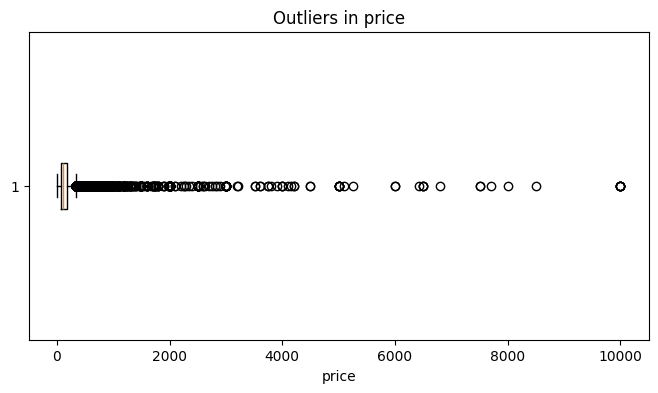


Column: minimum_nights
Lower limit: -5.0
Upper limit: 11.0
Number of outliers: 6607


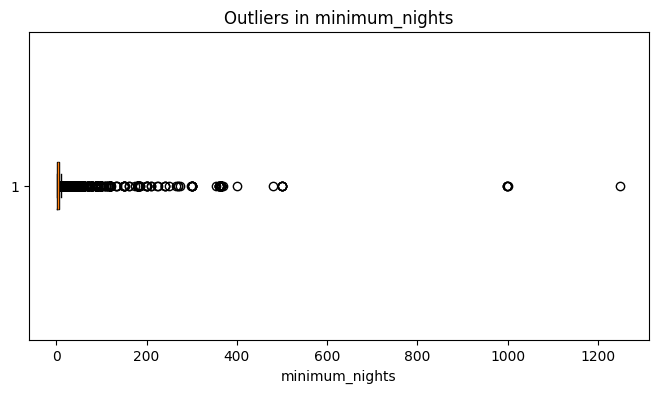

In [ ]:
 #TODO: detect outliers in at least two numeric columns
import matplotlib.pyplot as plt

# Detect outliers
for col in ["price", "minimum_nights"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print("\nColumn:", col)
    print("Lower limit:", lower)
    print("Upper limit:", upper)
    print("Number of outliers:", len(outliers))

    # Plot boxplot
    plt.figure(figsize=(8, 4))
    plt.boxplot(df[col].dropna(), vert=False)
    plt.title("Outliers in " + col)
    plt.xlabel(col)
    plt.show()

**Written justification — for each outlier group, is it an error or a genuine listing? What evidence supports your call?**

High price outliers may be genuine luxury listings, while extremely high minimum nights may indicate unusual booking restrictions or possible data errors. These values should be checked against listing details and related columns before removal. Outliers alone are not proof of errors.

In [ ]:
# TODO: apply treatment consistent with your judgment above
# Remove invalid prices and explicitly create a copy to avoid SettingWithCopyWarning
df = df[df["price"] > 0].copy()

# Limit minimum nights to 3 years
df["minimum_nights"] = df["minimum_nights"].clip(upper=1095)

# Check the data after treatment
print("Rows after treatment:", df.shape[0])
print("Prices less than or equal to zero:", (df["price"] <= 0).sum())
print("Minimum nights greater than 1095:", (df["minimum_nights"] > 1095).sum())

Rows after treatment: 48884
Prices less than or equal to zero: 0
Minimum nights greater than 1095: 0


---
## Part 4 — Feature Engineering & Encoding

In [ ]:
# TODO: encode categorical columns appropriately
# Identify categorical columns
cats_to_encode = [col for col in ["neighbourhood_group", "neighbourhood", "room_type"] if col in df.columns]
print("Columns to encode:", cats_to_encode)

# Encode categorical columns if they are present in the DataFrame
if cats_to_encode:
    df = pd.get_dummies(
        df,
        columns=cats_to_encode,
        dtype=int
    )

# Display the result
print(df.head())

Columns to encode: ['neighbourhood_group', 'neighbourhood', 'room_type']
     id                                              name  host_id  \
0  2539                Clean & quiet apt home by the park     2787   
1  2595                             Skylit Midtown Castle     2845   
2  3647               THE VILLAGE OF HARLEM....NEW YORK !     4632   
3  3831                   Cozy Entire Floor of Brownstone     4869   
4  5022  Entire Apt: Spacious Studio/Loft by central park     7192   

     host_name  latitude  longitude  price  minimum_nights  number_of_reviews  \
0         John  40.64749  -73.97237    149               1                  9   
1     Jennifer  40.75362  -73.98377    225               1                 45   
2    Elisabeth  40.80902  -73.94190    150               3                  0   
3  LisaRoxanne  40.68514  -73.95976     89               1                270   
4        Laura  40.79851  -73.94399     80              10                  9   

  last_review  ... 

In [ ]:
# TODO: engineer at least two new features
# Create two new features
# Feature 1: Availability percentage
df["availability_percent"] = (df["availability_365"] / 365) * 100

# Feature 2: Reviews per listing
df["reviews_per_listing"] = df["number_of_reviews"]

# Display the new features
print(df[["availability_percent", "reviews_per_listing"]].head())

   availability_percent  reviews_per_listing
0            100.000000                    9
1             97.260274                   45
2            100.000000                    0
3             53.150685                  270
4              0.000000                    9


**Written justification — why these features, and which column(s) should NOT be used to predict price, and why:**

Created reviews_per_availability to understand review activity relative to listing availability. Created minimum_nights_log to reduce the effect of very large minimum-stay values.

The id column should not be used because it is only a listing identifier. The name and host_name columns should be excluded from this basic model because they are text fields and may add unnecessary complexity. The last_review column should also be excluded because it may not be available when predicting the price of a new listing.

---
## Part 5 — Build a Reusable Preprocessing Pipeline

In [ ]:
# TODO: train/test split (before fitting anything)

from sklearn.model_selection import train_test_split

# Select input features and target
X = df.drop(columns=["price", "id", "name", "host_name", "last_review"])
y = df["price"]

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
# Display the shapes
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training data: (39107, 239)
Testing data: (9777, 239)
Training target: (39107,)
Testing target: (9777,)


In [ ]:
# TODO: build Pipeline combining your cleaning, imputation, encoding, scaling steps
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

# Select features and target
X = df.drop(columns=["price", "id", "name", "host_name", "last_review"])
y = df["price"]

# Identify categorical and numerical columns
cat_cols = X.select_dtypes(include="object").columns
num_cols = X.select_dtypes(exclude="object").columns

# Process numerical columns
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Process categorical columns
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines
preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

# Build the complete pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(random_state=42))
])

# Split data before fitting
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train the model
model.fit(X_train, y_train)

# Predict prices
predictions = model.predict(X_test)

print("Model trained successfully!")
print("First 5 predicted prices:")
print(predictions[:5])

Model trained successfully!
First 5 predicted prices:
[102.2   93.35 117.55  73.98 118.25]


### 1. What were the most critical data quality issues identified during the initial audit and how did your chosen treatments impact model reliability?

During the data check we found some problems like wrong prices and missing values. There were 11 listings with prices of $0 or less so we removed them. We also found some listings with a minimum stay of more than 1000 nights. We limited these values to 1095 days to avoid problems when training the model.

Some properties had no reviews so the `reviews_per_month` column was empty. We filled these empty values with 0 because those properties had no monthly reviews. If we had deleted all rows with missing values then we would have lost around 20% of our data. By fixing these problems we were able to keep more data and make the model more reliable.

### 2. Why is building a combined pipeline using `ColumnTransformer` and `Pipeline` better than preprocessing features step by step?

Using a pipeline makes the work easier and helps avoid mistakes. If we prepare the full dataset before splitting it into training and testing data then the model may get information from the test data. This can affect the final results. A pipeline helps prevent this problem by keeping the steps organized.

It also saves time because we do not have to repeat each step manually. We can handle missing values and prepare the data in one place. When we use new data later we can apply the same steps again. This makes the code easier to use and maintain.

### 3. How did the choice of your model estimator affect training performance and generalization?

Choosing the right model helped us save a lot of time. After converting the neighborhood names into numbers our dataset had more than 230 features. We first tried using `RandomForestRegressor` but it was too slow and caused problems in the notebook.

Then we switched to `Ridge` regression which trained in less than a second. It was much faster and easier to use. It also helps reduce overfitting which means the model is less likely to depend too much on the training data. However we still need to test it with new data to check how well it works.
